In [122]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression,LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.ensemble import GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

In [15]:
df = pd.read_csv("C:/Users/Admin/Downloads/archive/csvdata.csv")
df.head()

,Unnamed: 0,City,Price,Area,Location,No. of Bedrooms
0,0,Bangalore,30000000,3340,JP Nagar Phase 1,4
1,1,Bangalore,7888000,1045,Dasarahalli on Tumkur Road,2
2,2,Bangalore,4866000,1179,Kannur on Thanisandra Main Road,2
3,3,Bangalore,8358000,1675,Doddanekundi,3
4,4,Bangalore,6845000,1670,Kengeri,3


In [17]:
df.shape

(29135, 6)

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29135 entries, 0 to 29134
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Unnamed: 0       29135 non-null  int64 
 1   City             29135 non-null  object
 2   Price            29135 non-null  int64 
 3   Area             29135 non-null  int64 
 4   Location         29135 non-null  object
 5   No. of Bedrooms  29135 non-null  int64 
dtypes: int64(4), object(2)
memory usage: 1.3+ MB


In [23]:
df.describe().sum()

Unnamed: 0         5.069648e+04
Price              9.158233e+08
Area               5.091568e+04
No. of Bedrooms    2.915524e+04
dtype: float64

In [26]:
print("Mising values",df.isnull().sum().sum())

Mising values 0


In [33]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [34]:
print("Column names:", df.columns.tolist())

Column names: ['Unnamed: 0', 'City', 'Price', 'Area', 'Location', 'No. of Bedrooms']


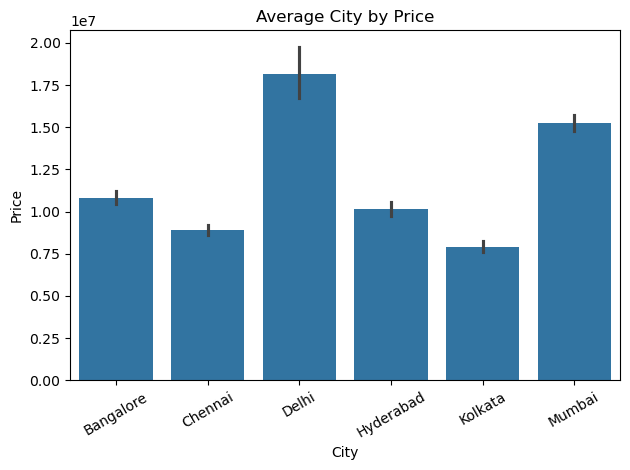

In [27]:
sns.barplot(data=df,x="City",y="Price", estimator="mean")
plt.title("Average City by Price")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [42]:
# Remove the exported DataFrame index column; it is not a house feature.

df = df.drop(columns=["Unnamed:0"],errors="ignore")

# Standardise column names for easier coding.
df = df.rename(columns={
    "No.of Bedrooms" : "Bedrooms"
})

# Convert numeric columns safely.
for col in ["Price","Area","Bedrooms"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows missing target or essential numeric predictors.
df = df.dropna(subset=["Price","Area","Bedrooms"]).copy()

# Remove impossible/non-useful values.
df = df[(df["Price"] > 0) & (df["Area"] > 0)&(df["Bedrooms"] > 0)].copy()

# Clean categorical text.
for col in ["City","Location"]:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace(" ", pd.NA)

# Remove exact duplicate records after cleaning.
df = df.drop_duplicates().reset_index(drop = True)

print("Cleaned dataset shape:", df.shape)


Cleaned dataset shape: (28398, 5)


In [43]:
display(df.head())

,City,Price,Area,Location,Bedrooms
0,Bangalore,30000000,3340,JP Nagar Phase 1,4
1,Bangalore,7888000,1045,Dasarahalli on Tumkur Road,2
2,Bangalore,4866000,1179,Kannur on Thanisandra Main Road,2
3,Bangalore,8358000,1675,Doddanekundi,3
4,Bangalore,6845000,1670,Kengeri,3


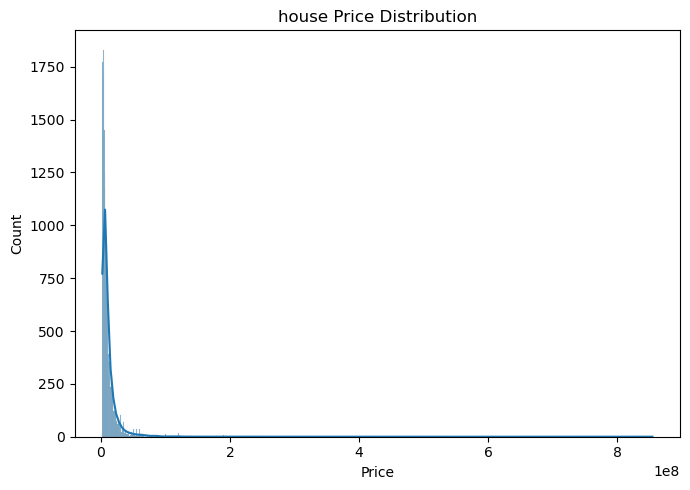

In [65]:
plt.subplots(figsize=(7, 5))
sns.histplot(df["Price"], kde=True)
plt.title("house Price Distribution")
plt.xlabel("Price")
plt.tight_layout()
plt.show()

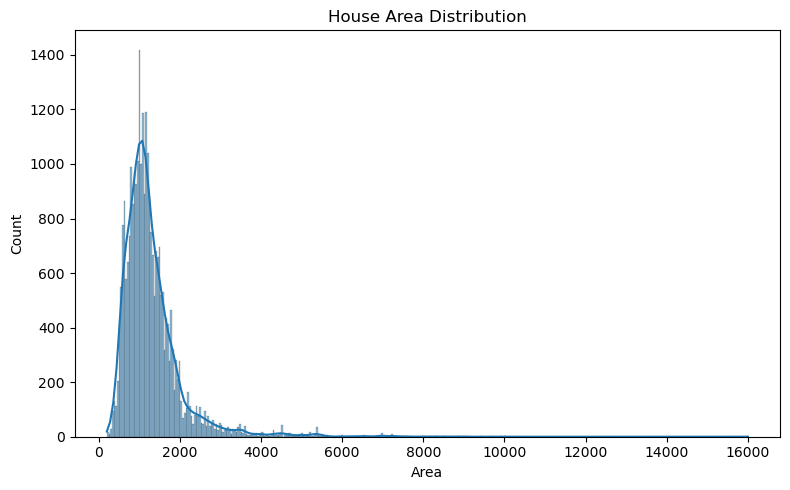

In [66]:
plt.subplots(figsize=(8,5))
sns.histplot(df["Area"], kde=True)
plt.title("House Area Distribution")
plt.xlabel("Area")
plt.tight_layout()
plt.show()

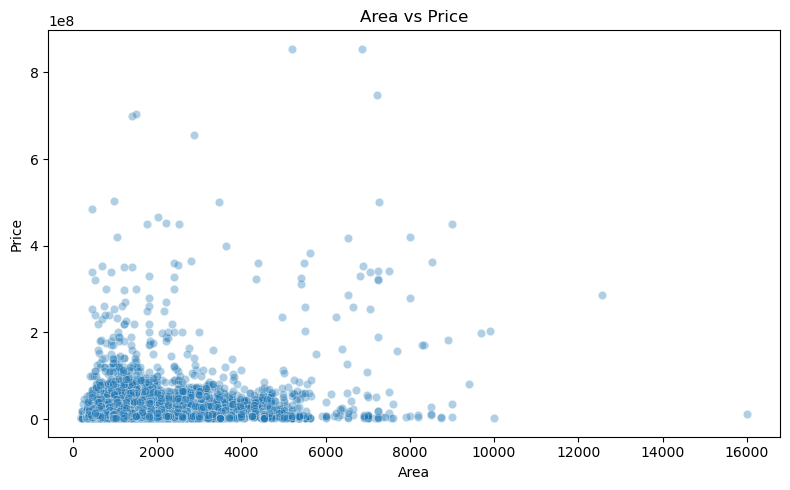

In [70]:
# Price vs area and bedroom count

plt.subplots(figsize=(8,5))
sns.scatterplot(data = df,
                x="Area",
                y="Price",
                alpha=0.35)
plt.title("Area vs Price")
plt.tight_layout()
plt.show()

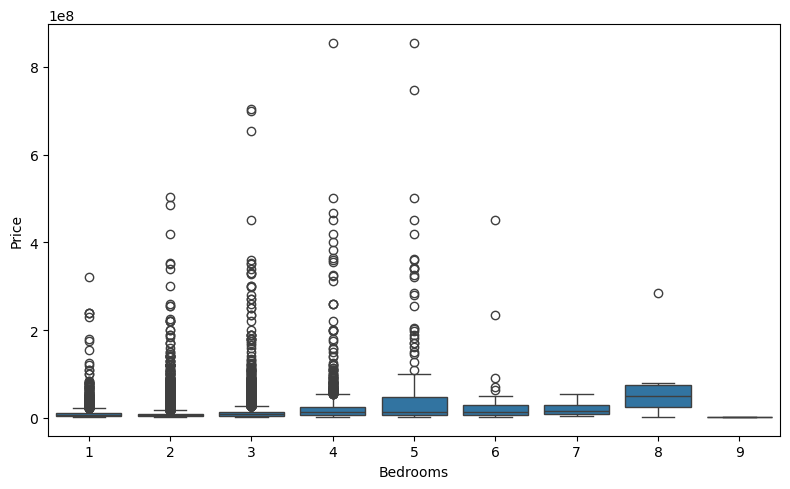

In [105]:
plt.subplots(figsize=(8,5))
sns.boxplot(data = df, 
            x="Bedrooms",
            y="Price")
plt.tight_layout()
plt.show()

In [79]:
print("Records by City:")
df["City"].value_counts()

Records by City:


City
Mumbai       6820
Kolkata      6270
Bangalore    5438
Chennai      4208
Delhi        3859
Hyderabad    1803
Name: count, dtype: Int64

In [88]:
# City-level median price: useful for understanding market differences.

city_summary = (
    df.groupby("City")["Price"]
    .agg(["count","median","mean"])
    .sort_values("median", ascending=False)
)
display(city_summary)
    

,count,median,mean
City,,,
Mumbai,6820,9500000.0,1.534916e+07
Delhi,3859,8000000.0,1.872712e+07
Hyderabad,1803,7800000.0,1.019267e+07
Bangalore,5438,7276500.0,1.082805e+07
Chennai,4208,5844500.0,8.916339e+06
Kolkata,6270,4922000.0,7.909196e+06


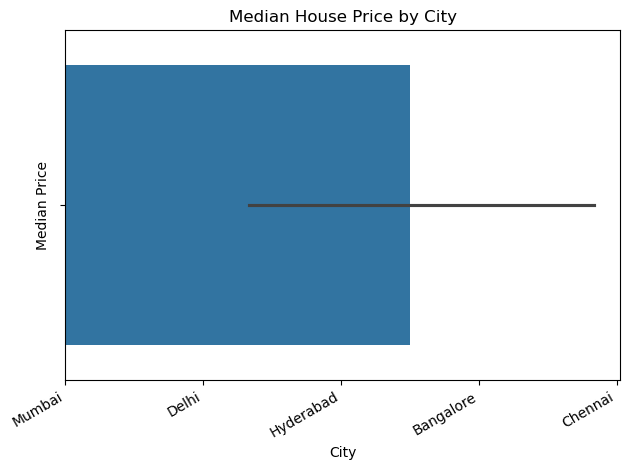

In [107]:
sns.barplot(data=city_summary.reset_index(), x="City")
plt.xticks(rotation=30, ha="right")
plt.ylabel("Median Price")
plt.title("Median House Price by City")
plt.tight_layout()
plt.show()

In [114]:
target = "Price"
features = ["City", "Area", "Location", "Bedrooms"]

X = df.drop('Price', axis=1)
y = df['Price']

numeric_features = ["Area","Bedrooms"]
categoraical_features = ["City", "Location"]

In [116]:
X_train, X_test,y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    random_state = 42
)
print("Training records:",len(X_train))
print("Testing records:",len(X_test))

Training records: 22718
Testing records: 5680


In [119]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10
    ))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])


In [125]:
models = {
    "Linear Regression" : LinearRegression(),
    "Decision Tree" : DecisionTreeRegressor(random_state=42),
    "Random Forest" : RandomForestRegressor(n_estimators=100,random_state = 42),
    "Extra Trees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting" : GradientBoostingRegressor(random_state=42)
}


In [132]:
cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

results = []
pipelines = {}

for name,estimator in models.items():
    print(f"Training : {name}...",flush=True)
    

Training : Linear Regression...
Training : Decision Tree...
Training : Random Forest...
Training : Extra Trees...
Training : Gradient Boosting...


In [147]:
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    cv_scores = cross_val_score(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=1
    )

    results.append({
        "Model": name,
        "CV_RMSE_Mean": -cv_scores.mean(),
        "CV_RMSE_Std": cv_scores.std()
    })

    pipelines[name] = pipe

    print(f"Completed: {name}", flush=True)

comparison = pd.DataFrame(results).sort_values(
    "CV_RMSE_Mean",
    ascending=True
)

print(comparison)

Completed: Gradient Boosting
               Model  CV_RMSE_Mean   CV_RMSE_Std
0  Gradient Boosting  2.289812e+07  1.399484e+06
1  Gradient Boosting  2.289812e+07  1.399484e+06
2  Gradient Boosting  2.289812e+07  1.399484e+06
3  Gradient Boosting  2.289812e+07  1.399484e+06
4  Gradient Boosting  2.289812e+07  1.399484e+06
5  Gradient Boosting  2.289812e+07  1.399484e+06
6  Gradient Boosting  2.289812e+07  1.399484e+06
7  Gradient Boosting  2.289812e+07  1.399484e+06
8  Gradient Boosting  2.289812e+07  1.399484e+06


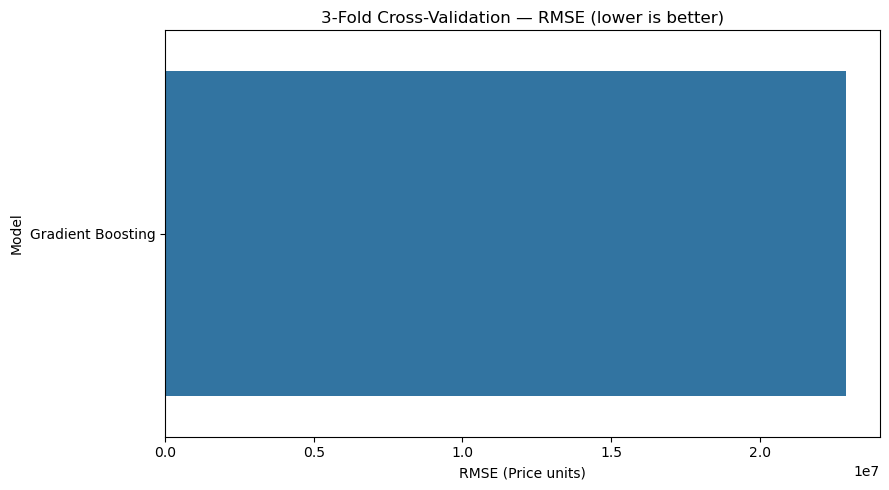

In [148]:
plt.figure(figsize=(9, 5))
sns.barplot(data=comparison, x="CV_RMSE_Mean", y="Model")
plt.title("3-Fold Cross-Validation — RMSE (lower is better)")
plt.xlabel("RMSE (Price units)")
plt.tight_layout()
plt.show()

In [149]:
best_name = comparison.iloc[0]["Model"]
best_model = pipelines[best_name]

best_model.fit(X_train, y_train)
predictions = best_model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("Best model:", best_name)
print(f"MAE : {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R²  : {r2:.4f}")

Best model: Gradient Boosting
MAE : 7,621,503.91
RMSE: 21,620,261.46
R²  : 0.1304


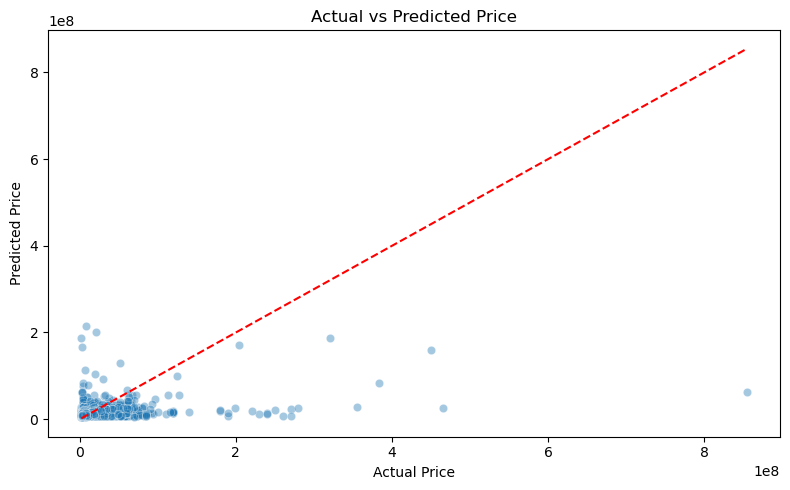

In [160]:
low = min(y_test.min(), predictions.min())
high = max(y_test.max(), predictions.max())

plt.subplots(figsize=(8,5))
sns.scatterplot(x=y_test, y=predictions, alpha=0.4)
plt.plot([low, high], [low, high], "r--")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Price")
plt.tight_layout()
plt.show()

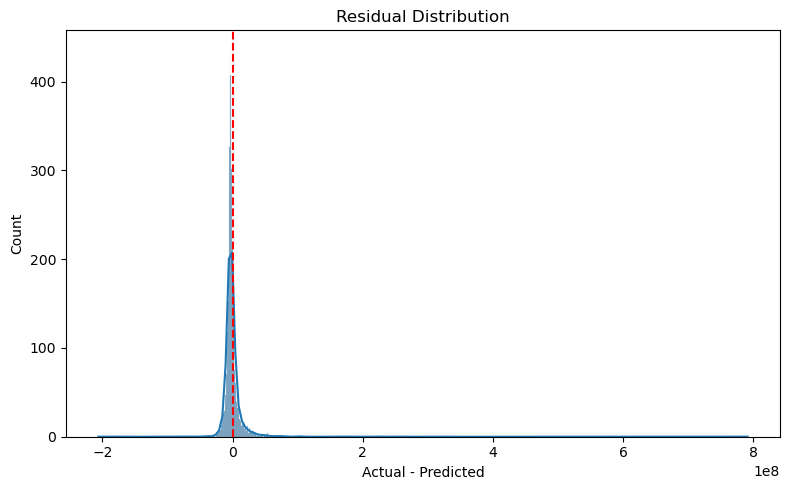

In [163]:
plt.subplots(figsize=(8,5))
residuals = y_test - predictions
sns.histplot(residuals, kde=True)
plt.axvline(0, color="red", linestyle="--")
plt.title("Residual Distribution")
plt.xlabel("Actual - Predicted")
plt.tight_layout()
plt.show()

In [170]:
new_house = pd.DataFrame([{
    "City": "Chennai",
    "Area": 1200,
    "Location": "Anna Nagar",
    "Bedrooms": 2
}])

predicted_price = best_model.predict(new_house)[0]
print(f"Estimated house price: ₹{predicted_price:,.0f}")

Estimated house price: ₹8,279,422


In [171]:
import joblib
model_file = "best_home_price_model.pkt"
joblib.dump(best_model, model_file)
print("Best Model Saved Successfully!")
print("Model:",best_name)
print("File:",model_file)

Best Model Saved Successfully!
Model: Gradient Boosting
File: best_home_price_model.pkt
